# EMQA_L3_fc_test

**Absolute daily EUR/MWh shocks of the Romanian base price over the test year 2025-11-01 to 2026-10-31 with the one-day-ahead GARCH(1,1)-t volatility forecast and the 30-day historical volatility, both re-estimated every day with the data up to the day before: GARCH reacts at once, the 30-day history lags and then forgets the shock abruptly 30 days later.**

Energy Markets Quantitative Analysis (EMQA), Lecture 3 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L3/EMQA_L3_fc_test/EMQA_L3_fc_test.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.titlesize': 11.5, 'axes.labelsize': 11,
    'legend.fontsize': 10.5, 'legend.frameon': False, 'lines.linewidth': 1.4})
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}
C_PCT, C_EUR = PAL['RO'], PAL['c7']          # percent changes, EUR/MWh changes


def legend_bottom(fig, handles=None, labels=None, ncol=4, y=0.0):
    # legend centred under the axes, outside the plotting area
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for h, l in zip(*ax.get_legend_handles_labels()):
                if l not in labels:
                    handles.append(h)
                    labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, y), frameon=False,
               handlelength=2.0, columnspacing=1.2)


def slide(label, key, x, k=None):
    # prints a number shown on the slide; [key] = its name in lectures/L3/L3_numbers.json
    if k is not None:
        x = round(float(x), k)
    print(f'{label:<58s} {x}   [{key}]')

In [3]:
# Romanian daily base price (mean of all MTUs of the CET/CEST delivery day), EUR/MWh
PD = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', usecols=['date_cet', 'RO'], parse_dates=['date_cet']).set_index('date_cet')
# cut-off = last complete month; panel from 2019-01-01, on the full calendar
_last = PD['RO'].dropna().index.max()
END = pd.Timestamp(((_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
START = pd.Timestamp('2019-01-01')
CAL = pd.date_range(START, END, freq='D')
P = PD['RO'].reindex(CAL)
print('Romania, daily base price:', START.date(), 'to', END.date(), '|', len(CAL), 'days, missing:', int(P.isna().sum()))

Romania, daily base price: 2019-01-01 to 2026-10-31 | 2861 days, missing: 0


In [4]:
# daily changes on the full calendar: percent (log) and EUR/MWh
r = 100 * np.log(P.where(P > 0)).diff()      # r_t = 100 ln(P_t / P_{t-1}); missing if a price is <= 0
u = P.diff()                                  # Delta P_t = P_t - P_{t-1}, EUR/MWh

## Rolling one-day-ahead GARCH-t forecasts

For every day $t$ of the test year (the last 365 days to the cut-off) the mean equation (constant + AR(1..7) + day-of-week dummies) and a GARCH(1,1)-t on its residuals are re-estimated on all EUR/MWh changes up to $t-1$; the 30-day historical variance is the mean of the last 30 squared residuals. The 365 re-estimations are kept out of the default run, so the results are loaded from `garch_t_rolling_eur.csv` (saved in this Quantlet by `lectures/L3/make_quantlets_L3.py` with exactly this code); set `RUN_ALL = True` to recompute them.

In [5]:
RUN_ALL = False    # True: recompute the 365 rolling GARCH-t forecasts (well under a minute on Colab); False: load them
TDAYS = pd.date_range(END - pd.Timedelta(days=364), END, freq='D')      # test year
if RUN_ALL:
    import statsmodels.api as sm


    def mean_design(y, lags=7):
        # constant + AR(1..7) + six day-of-week dummies (Monday = base)
        X = pd.DataFrame({f'L{k}': y.shift(k) for k in range(1, lags + 1)}, index=y.index)
        for j in range(1, 7):
            X[f'D{j}'] = (y.index.dayofweek == j).astype(float)
        X.insert(0, 'const', 1.0)
        return X


    def mean_fit(y, lags=7):
        # OLS mean equation; returns (residuals = shocks, fitted model)
        X = mean_design(y, lags)
        df = pd.concat([y.rename('y'), X], axis=1).dropna()
        m = sm.OLS(df['y'], df.drop(columns='y')).fit()
        return m.resid, m


    E_PCT, M_PCT = mean_fit(r)       # shocks epsilon_t, percent
    E_EUR, M_EUR = mean_fit(u)       # shocks u_t, EUR/MWh
    print('shocks:', E_PCT.index[0].date(), 'to', E_PCT.index[-1].date(), '|', len(E_PCT), 'days')

    try:
        import arch
    except ImportError:          # Google Colab: install the arch package once
        import subprocess, sys
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'arch'])
    from arch import arch_model


    def fit(e, vol='GARCH', o=0, dist='t'):
        # zero-mean GARCH(1,1) (o=0) or GJR-GARCH(1,1,1) (o=1), Student-t shocks by default
        return arch_model(np.asarray(e, float), mean='Zero', vol=vol, p=1, o=o, q=1, dist=dist,
                          rescale=False).fit(disp='off', show_warning=False)

    def one_day(y, t):
        # forecasts for day t from data up to t-1: mean equation re-estimated by OLS, then GARCH(1,1)-t on its residuals
        X = mean_design(y)
        df = pd.concat([y.rename('y'), X], axis=1)
        tr = df.loc[:t - pd.Timedelta(days=1)].dropna()
        Xt, yt = tr.drop(columns='y').values, tr['y'].values
        b = np.linalg.lstsq(Xt, yt, rcond=None)[0]
        e_tr = yt - Xt @ b
        yhat = float(df.loc[t].drop('y').values @ b)
        res = fit(e_tr)
        return {'y': float(df.loc[t, 'y']), 'yhat': yhat, 'e': float(df.loc[t, 'y']) - yhat,
                'hist30': float(np.mean(e_tr[-30:] ** 2)),                                  # 30-day historical variance
                'garch': float(res.forecast(horizon=1, reindex=False).variance.values[-1, 0]),  # GARCH-t variance forecast
                'nu': float(res.params['nu'])}

    R = pd.DataFrame([one_day(u.loc[START:END], t) for t in TDAYS], index=TDAYS)
else:
    # saved by lectures/L3/make_quantlets_L3.py with the code above
    R = pd.read_csv(REPO + 'Quantlets/L3/EMQA_L3_fc_test/garch_t_rolling_eur.csv', index_col=0, parse_dates=True)
    assert R.index.equals(TDAYS), 'saved forecasts do not match the test year of the data'
print('test year:', TDAYS[0].date(), 'to', TDAYS[-1].date(), '|', len(R), 'one-day-ahead forecasts')

test year: 2025-11-01 to 2026-10-31 | 365 one-day-ahead forecasts


### Numbers on the slide

The largest absolute shock of the test year and the two forecasts around it.

In [6]:
ts = R['e'].abs().idxmax()
k = R.index.get_loc(ts)
slide('largest shock of the test year, EUR/MWh', 'ghost.shock', R['e'].loc[ts], 1)
slide('  on', 'ghost.date', str(ts.date()))
slide('GARCH sigma on that day (made the day before)', 'ghost.garch_before', np.sqrt(R['garch'].iloc[k]), 1)
slide('GARCH sigma the next day', 'ghost.garch_after', np.sqrt(R['garch'].iloc[k + 1]), 1)
slide('30-day historical sigma the next day', 'ghost.hist_after', np.sqrt(R['hist30'].iloc[k + 1]), 1)
slide('30-day historical sigma 30 days later', 'ghost.hist_30', np.sqrt(R['hist30'].iloc[k + 30]), 1)
slide('30-day historical sigma 31 days later', 'ghost.hist_31', np.sqrt(R['hist30'].iloc[k + 31]), 1)

largest shock of the test year, EUR/MWh                    123.9   [ghost.shock]
  on                                                       2026-01-22   [ghost.date]
GARCH sigma on that day (made the day before)              25.2   [ghost.garch_before]
GARCH sigma the next day                                   47.0   [ghost.garch_after]
30-day historical sigma the next day                       32.9   [ghost.hist_after]
30-day historical sigma 30 days later                      31.9   [ghost.hist_30]
30-day historical sigma 31 days later                      22.6   [ghost.hist_31]


### Chart

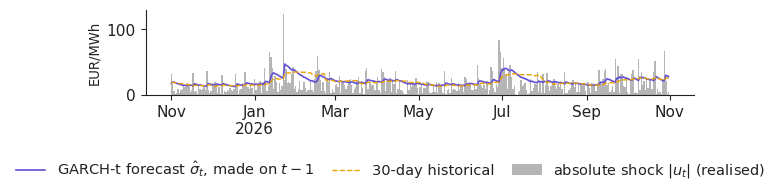

In [7]:
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
MON = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']


def yfmt(ax):
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))


def mfmt(ax, step=1):
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=step))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, p: MON[mdates.num2date(v).month - 1] +
                                               (f'\n{mdates.num2date(v).year}' if mdates.num2date(v).month == 1 else '')))
fig, ax = plt.subplots(figsize=(6.4, 2.0))
ax.bar(R.index, R['e'].abs(), color='#b5b5b5', width=1.0, label='absolute shock $|u_t|$ (realised)')
ax.plot(R.index, np.sqrt(R['garch']), color=C_EUR, lw=1.2, label=r'GARCH-t forecast $\hat\sigma_t$, made on $t-1$')
ax.plot(R.index, np.sqrt(R['hist30']), color=PAL['BG'], lw=1.0, ls='--', label='30-day historical')
ax.set_ylabel('EUR/MWh', fontsize=9.5)
mfmt(ax, 2)
legend_bottom(fig, ncol=3)
fig.tight_layout(rect=(0, 0.2, 1, 1))
plt.savefig('fc_test.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()